# 03 ML models: day-grouped nested validation

Target: log10(T/T0,raw) at 10 to 60 min (triplicate means). Scores on log10 turbidity. Outer leave-one-day-out, inner GroupKFold on training days, Optuna tuning. Predictions are cached in `results/predictions/03/`, so an interrupted run resumes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import time
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.exceptions import ConvergenceWarning

from src.config import DATA_PROC, RESULTS, SED_TIMES
from src.features import make_table
from src.cv import lodo, random_kfold, fold_ids
from src.metrics import scores
from src import models as M
from src import style

style.apply()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

N_TRIALS = 15
SUBSET_DAYS = None
FEATURE_SETS = {"core": ["dose", "log_t0_raw", "sed"],
                 "full": ["dose", "log_t0_raw", "sed", "speed", "mtime"]}
RUNS = [("core", "lodo"), ("core", "random"), ("full", "lodo")]
TARGET = "log_ratio"

PRED_DIR = RESULTS / "predictions" / "03"
MET_DIR = RESULTS / "metrics"
for p in (PRED_DIR, MET_DIR):
    p.mkdir(parents=True, exist_ok=True)

## 1. Model table and folds

In [2]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
if SUBSET_DAYS:
    long = long[long["day"].isin(sorted(long["day"].unique())[:SUBSET_DAYS])]
tab = make_table(long, level="cell")
groups = tab["day"].to_numpy()
folds = {"lodo": lodo(groups), "random": random_kfold(len(tab), 10)}
tab["fold_lodo"] = fold_ids(folds["lodo"], len(tab))
tab["fold_random"] = fold_ids(folds["random"], len(tab))
if not SUBSET_DAYS:
    tab.to_csv(DATA_PROC / "model_table.csv", index=False)
print(tab.shape, "rows,", tab["run"].nunique(), "runs,", tab["day"].nunique(), "days")
tab.groupby("day").size().describe().round(1)

(1008, 17) rows, 168 runs, 22 days


count     22.0
mean      45.8
std       19.8
min       36.0
25%       36.0
50%       36.0
75%       36.0
max      108.0
dtype: float64

Leakage checks.

In [3]:
feats = sorted(set(sum(FEATURE_SETS.values(), [])))
assert not set(feats) & {"turb", "log_turb", "log_ratio", "day", "date", "run", "batch"}
for tr, te in folds["lodo"]:
    assert not set(groups[tr]) & set(groups[te])
t0_rows = long[long["sed"] == 0]
assert tab["t0_raw"].between(t0_rows["turb"].min(), t0_rows["turb"].max()).all()
print("features:", feats)
print("lodo folds:", len(folds["lodo"]), "| no day in both train and test | T0_raw built from 0-min readings only")

features: ['dose', 'log_t0_raw', 'mtime', 'sed', 'speed']
lodo folds: 22 | no day in both train and test | T0_raw built from 0-min readings only


Replicate noise of a triplicate mean (reference floor for log10 RMSE).

In [4]:
d = long[long["sed"] > 0].assign(ly=np.log10(long["turb"]))
cell_var = d.groupby(["run", "sed"])["ly"].var(ddof=1)
noise_cell = np.sqrt(cell_var.mean() / 3)
print(f"replicate SD of a triplicate mean, log10: {noise_cell:.4f}")

replicate SD of a triplicate mean, log10: 0.0114


## 2. Run

In [5]:
y = tab[TARGET].to_numpy()
offset = tab["log_t0_raw"].to_numpy()
all_params, timing = [], []

for fs, split in RUNS:
    X = tab[FEATURE_SETS[fs]].to_numpy(float)
    for name in M.ALL:
        path = PRED_DIR / f"{name}__{fs}__{split}.csv"
        if path.exists():
            continue
        t = time.time()
        pred, std, params = M.run_cv(name, X, y, groups, folds[split], split, FEATURE_SETS[fs], N_TRIALS)
        out = tab[["run", "day", "sed", "t0_raw", "log_turb"]].assign(
            model=name, fset=fs, split=split, fold=tab[f"fold_{split}"],
            pred=pred + offset, std=std)
        out.to_csv(path, index=False)
        pd.DataFrame(params).assign(model=name, fset=fs, split=split).to_csv(
            PRED_DIR / f"params__{name}__{fs}__{split}.csv", index=False)
        timing.append((name, fs, split, round(time.time() - t, 1)))
        print(f"{name:10s} {fs:5s} {split:6s} {time.time() - t:7.1f} s")

preds = pd.concat([pd.read_csv(p) for p in sorted(PRED_DIR.glob("*__*__*.csv")) if not p.name.startswith("params")],
                  ignore_index=True)
preds = preds[preds["model"].isin(M.ALL)]
print(preds.shape)

sed_mean   core  lodo       0.0 s
linear     core  lodo       0.2 s
gp         core  lodo     384.6 s
ridge_poly core  lodo       5.7 s
svr        core  lodo      63.3 s
rf         core  lodo     443.8 s
et         core  lodo     280.6 s
hgb        core  lodo     515.4 s
mlp        core  lodo     565.2 s
sed_mean   core  random     0.0 s
linear     core  random     0.0 s
gp         core  random   188.4 s
ridge_poly core  random     6.5 s
svr        core  random    85.8 s
rf         core  random   470.6 s
et         core  random   121.5 s
hgb        core  random   287.2 s
mlp        core  random   132.2 s
sed_mean   full  lodo       0.0 s
linear     full  lodo       0.2 s
gp         full  lodo     981.0 s
ridge_poly full  lodo      14.3 s
svr        full  lodo     155.7 s
rf         full  lodo     957.4 s
et         full  lodo     318.5 s
hgb        full  lodo     427.9 s
mlp        full  lodo     745.8 s
(27216, 11)


## 3. Scores

In [6]:
def removal(log_t, t0):
    return 100 * (1 - 10 ** log_t / t0)

rows, by_day = [], []
for (m, fs, sp), g in preds.groupby(["model", "fset", "split"]):
    s = scores(g["log_turb"], g["pred"])
    day_rmse = np.sqrt(g.assign(se=(g["pred"] - g["log_turb"]) ** 2).groupby("day")["se"].mean())
    g60 = g[g["sed"] == 60]
    s.update({
        "model": m, "fset": fs, "split": sp,
        "day_rmse_mean": day_rmse.mean(), "day_rmse_sd": day_rmse.std(),
        "rmse_log_60": np.sqrt(np.mean((g60["pred"] - g60["log_turb"]) ** 2)),
        "mae_removal60_pp": np.mean(np.abs(removal(g60["pred"], g60["t0_raw"]) - removal(g60["log_turb"], g60["t0_raw"]))),
    })
    rows.append(s)
    by_day.append(day_rmse.rename("rmse").reset_index().assign(model=m, fset=fs, split=sp))

score_tab = pd.DataFrame(rows).set_index(["fset", "split", "model"]).sort_index()
by_day = pd.concat(by_day, ignore_index=True)
score_tab.round(4).to_csv(MET_DIR / "03_scores.csv")
by_day.to_csv(MET_DIR / "03_scores_by_day.csv", index=False)
cols = ["day_rmse_mean", "day_rmse_sd", "rmse_log", "r2_log", "rmse_log_60", "mae_removal60_pp", "mape"]
score_tab[cols].round(4)

day_rmse_mean  day_rmse_sd  rmse_log  r2_log  rmse_log_60  mae_removal60_pp     mape
fset split  model                                                                                           
core lodo   et                 0.1574       0.0754    0.1730  0.6199       0.2042            8.7471  32.3248
            gp                 0.2811       0.0845    0.2809 -0.0026       0.2910           13.3229  57.8980
            hgb                0.1555       0.0723    0.1750  0.6110       0.1986            9.0616  32.8270
            linear             0.1509       0.0796    0.1653  0.6526       0.1910            8.2586  30.1028
            mlp                0.1396       0.0825    0.1596  0.6762       0.1928            8.0525  28.5227
            rf                 0.1570       0.0749    0.1716  0.6259       0.2016            8.7535  32.5552
            ridge_poly         0.1417       0.0838    0.1607  0.6718       0.1886            8.0052  29.0728
            sed_mean           0.2616       0.1312    0.2794  0.0079       0.3129           14.7574  62.7428
            svr                0.1418       0.0805    0.1592  0.6781       0.1898            8.0050  29.0235
     random et                 0.0848       0.0414    0.0914  0.8938       0.1157            4.8501  15.5362
            gp                 0.0264       0.0079    0.0272  0.9906       0.0237            1.0275   4.6185
            hgb                0.0417       0.0152    0.0425  0.9771       0.0566            2.9321   7.1179
            linear             0.1440       0.0746    0.1561  0.6905       0.1808            7.8866  28.2150
            mlp                0.1257       0.0721    0.1417  0.7447       0.1683            7.0458  24.2343
            rf                 0.0777       0.0424    0.0842  0.9099       0.1023            4.5974  14.0616
            ridge_poly         0.1281       0.0729    0.1440  0.7366       0.1722            7.4310  25.7226
            sed_mean           0.2539       0.1259    0.2697  0.0761       0.3027           14.2956  60.0745
            svr                0.1265       0.0805    0.1460  0.7290       0.1720            7.0268  25.1514
full lodo   et                 0.1193       0.0690    0.1332  0.7744       0.1633            7.4896  23.2803
            gp                 0.2299       0.0892    0.2377  0.2822       0.2483           10.8477  43.7398
            hgb                0.1281       0.0635    0.1472  0.7247       0.1699            7.6154  26.3867
            linear             0.1299       0.0579    0.1465  0.7274       0.1694            8.3396  28.4436
            mlp                0.1598       0.1138    0.2121  0.4282       0.2367           10.2765  36.9839
            rf                 0.1355       0.0755    0.1491  0.7175       0.1747            7.6415  27.3965
            ridge_poly         0.1371       0.0582    0.1524  0.7049       0.1742            8.3305  30.1492
            sed_mean           0.2616       0.1312    0.2794  0.0079       0.3129           14.7574  62.7428
            svr                0.1229       0.0584    0.1413  0.7464       0.1653            8.2016  28.0842

In [7]:
gap = score_tab.loc["core"]["day_rmse_mean"].unstack("split")
gap["random_over_lodo"] = gap["random"] / gap["lodo"]
fs_cmp = score_tab.xs("lodo", level="split")["day_rmse_mean"].unstack("fset")
fs_cmp["full_minus_core"] = fs_cmp["full"] - fs_cmp["core"]
display(gap.round(4))
fs_cmp.round(4)

split,lodo,random,random_over_lodo
model,,,
et,0.1574,0.0848,0.5389
gp,0.2811,0.0264,0.0940
hgb,0.1555,0.0417,0.2683
linear,0.1509,0.1440,0.9540
mlp,0.1396,0.1257,0.9001
rf,0.1570,0.0777,0.4949
ridge_poly,0.1417,0.1281,0.9037
sed_mean,0.2616,0.2539,0.9705
svr,0.1418,0.1265,0.8922


fset,core,full,full_minus_core
model,,,
et,0.1574,0.1193,-0.0381
gp,0.2811,0.2299,-0.0512
hgb,0.1555,0.1281,-0.0274
linear,0.1509,0.1299,-0.0210
mlp,0.1396,0.1598,0.0202
rf,0.1570,0.1355,-0.0215
ridge_poly,0.1417,0.1371,-0.0047
sed_mean,0.2616,0.2616,0.0000
svr,0.1418,0.1229,-0.0189


figures/models/fig01_model_scores.png


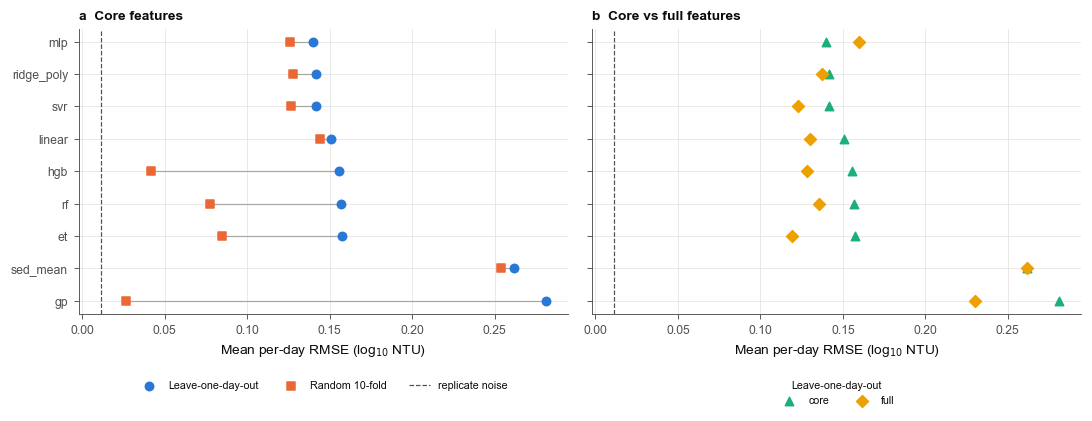

In [8]:
order = score_tab.loc[("core", "lodo")]["day_rmse_mean"].sort_values().index.tolist()
ypos = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
ax = axes[0]
for i, (sp, lab) in enumerate([("lodo", "Leave-one-day-out"), ("random", "Random 10-fold")]):
    v = score_tab.loc[("core", sp)].loc[order, "day_rmse_mean"]
    ax.scatter(v, ypos, color=style.COLORS[i], marker=style.MARKERS[i], s=30, label=lab, zorder=3)
for j, m in enumerate(order):
    a, b = (score_tab.loc[("core", sp, m), "day_rmse_mean"] for sp in ("lodo", "random"))
    ax.plot([a, b], [j, j], color=style.MUTED, lw=0.8, zorder=1)
ax.axvline(noise_cell, color=style.INK2, lw=0.8, ls="--", label="replicate noise")
ax.set_yticks(ypos, order)
ax.invert_yaxis()
ax.set_xlabel("Mean per-day RMSE (log$_{10}$ NTU)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=7)
style.panel_label(ax, "a  Core features")

ax = axes[1]
for i, fs in enumerate(["core", "full"]):
    v = score_tab.loc[(fs, "lodo")].loc[order, "day_rmse_mean"]
    ax.scatter(v, ypos, color=style.COLORS[i + 2], marker=style.MARKERS[i + 2], s=30, label=fs, zorder=3)
ax.axvline(noise_cell, color=style.INK2, lw=0.8, ls="--")
ax.set_xlabel("Mean per-day RMSE (log$_{10}$ NTU)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7, title="Leave-one-day-out", title_fontsize=7)
style.panel_label(ax, "b  Core vs full features")
fig.tight_layout()
print(style.save(fig, "fig01_model_scores", "models"))
plt.show()

figures/models/fig02_per_day_rmse.png


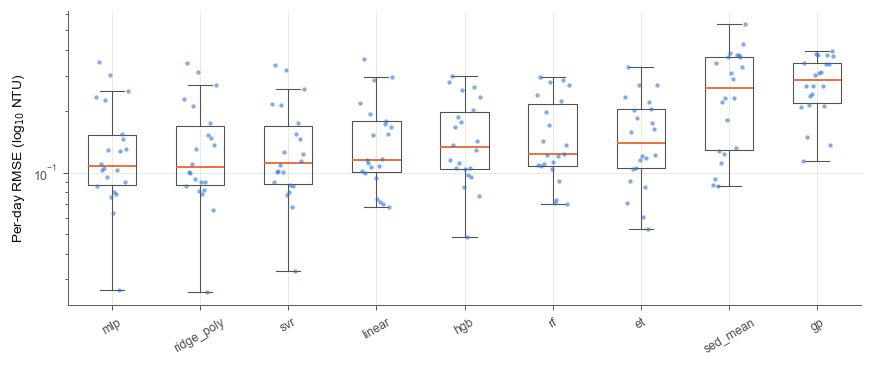

In [9]:
d = by_day[(by_day["fset"] == "core") & (by_day["split"] == "lodo")]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([d.loc[d["model"] == m, "rmse"] for m in order], positions=ypos, widths=0.55, showfliers=False,
           medianprops=dict(color=style.COLORS[1], lw=1.2), boxprops=dict(color=style.INK2, lw=0.7),
           whiskerprops=dict(color=style.INK2, lw=0.7), capprops=dict(color=style.INK2, lw=0.7))
for j, m in enumerate(order):
    v = d.loc[d["model"] == m, "rmse"]
    ax.scatter(j + np.linspace(-0.18, 0.18, len(v)), v, s=8, color=style.COLORS[0], alpha=0.6, lw=0, zorder=3)
ax.set_xticks(ypos, order, rotation=30)
ax.set_ylabel("Per-day RMSE (log$_{10}$ NTU)")
ax.set_yscale("log")
fig.tight_layout()
print(style.save(fig, "fig02_per_day_rmse", "models"))
plt.show()

figures/models/fig03_obs_vs_pred_best.png


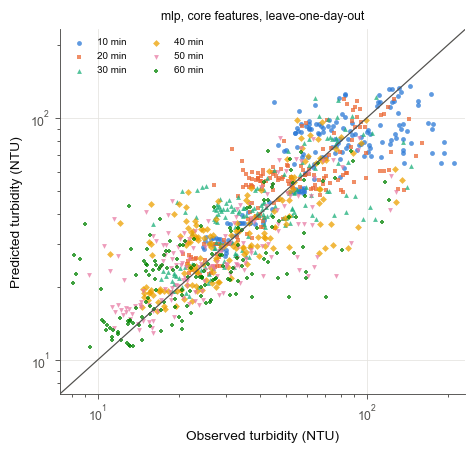

In [10]:
best = order[0]
g = preds[(preds["model"] == best) & (preds["fset"] == "core") & (preds["split"] == "lodo")]
fig, ax = plt.subplots(figsize=(4.4, 4.2))
for i, s in enumerate(SED_TIMES[1:]):
    h = g[g["sed"] == s]
    ax.scatter(10 ** h["log_turb"], 10 ** h["pred"], s=10, color=style.COLORS[i], marker=style.MARKERS[i],
               lw=0, alpha=0.75, label=f"{s} min")
lim = [10 ** min(g["log_turb"].min(), g["pred"].min()) * 0.9, 10 ** max(g["log_turb"].max(), g["pred"].max()) * 1.1]
ax.plot(lim, lim, color=style.INK2, lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Observed turbidity (NTU)")
ax.set_ylabel("Predicted turbidity (NTU)")
ax.set_title(f"{best}, core features, leave-one-day-out", fontsize=8)
ax.legend(fontsize=6.5, loc="upper left", ncol=2)
fig.tight_layout()
print(style.save(fig, "fig03_obs_vs_pred_best", "models"))
plt.show()

## 4. Selected hyperparameters (leave-one-day-out, core)

In [11]:
par = pd.concat([pd.read_csv(p) for p in sorted(PRED_DIR.glob("params__*__core__lodo.csv"))], ignore_index=True)
par = par[par["model"].isin(M.TUNED)]
summary = {}
for m, g in par.groupby("model"):
    g = g.drop(columns=["fold", "model", "fset", "split"]).dropna(axis=1, how="all")
    summary[m] = {c: (g[c].median() if pd.api.types.is_numeric_dtype(g[c]) else g[c].mode().iloc[0]) for c in g}
pd.DataFrame(summary).T

,max_features,min_samples_leaf,learning_rate,max_leaf_nodes,l2_regularization,max_iter,width,depth,alpha,learning_rate_init,max_depth,degree,C,gamma,epsilon
et,0.602362,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hgb,NaN,39.0,0.010389,4.0,1.430924,561.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mlp,NaN,NaN,NaN,NaN,NaN,NaN,51.0,2.0,0.001012,0.000233,NaN,NaN,NaN,NaN,NaN
rf,0.602362,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN
ridge_poly,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.507206,NaN,NaN,2.0,NaN,NaN,NaN
svr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.617423,0.007476,0.016738


## 5. Key numbers

In [12]:
key = {
    "noise_cell_log10": round(float(noise_cell), 4),
    "best_core_lodo": best,
    "best_core_lodo_day_rmse": round(float(score_tab.loc[("core", "lodo", best), "day_rmse_mean"]), 4),
    "sed_mean_core_lodo_day_rmse": round(float(score_tab.loc[("core", "lodo", "sed_mean"), "day_rmse_mean"]), 4),
    "random_over_lodo_median": round(float(gap["random_over_lodo"].median()), 3),
    "n_trials": N_TRIALS,
}
(MET_DIR / "03_key_numbers.json").write_text(json.dumps(key, indent=2))
pd.Series(key)

noise_cell_log10               0.0114
best_core_lodo                    mlp
best_core_lodo_day_rmse        0.1396
sed_mean_core_lodo_day_rmse    0.2616
random_over_lodo_median         0.892
n_trials                           15
dtype: object